#Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gamma
import seaborn as sns

#3 Part A: Maternal Smoking (EDA)

1) Loading the data into a Pandas Dataframe

In [2]:
cols = ["bwt", "gestation", "parity", "age", "height", "weight", "smoke"]
df = pd.read_csv("/content/babies.data", sep="\s+")

<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1771/4073645808.py:2: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv("/content/babies.data", sep="\s+")


In [3]:
#Checking if dataset loaded correctly

print (df.shape)
print (df.info())
print (df.head(10))

(1236, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1236 entries, 0 to 1235
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   bwt        1236 non-null   int64
 1   gestation  1236 non-null   int64
 2   parity     1236 non-null   int64
 3   age        1236 non-null   int64
 4   height     1236 non-null   int64
 5   weight     1236 non-null   int64
 6   smoke      1236 non-null   int64
dtypes: int64(7)
memory usage: 67.7 KB
None
   bwt  gestation  parity  age  height  weight  smoke
0  120        284       0   27      62     100      0
1  113        282       0   33      64     135      0
2  128        279       0   28      64     115      1
3  123        999       0   36      69     190      0
4  108        282       0   23      67     125      1
5  136        286       0   25      62      93      0
6  138        244       0   33      62     178      0
7  132        245       0   23      65     140      0
8  120      

In [4]:
#Cleaning up data that is unavailable
#We remove a row if: bwt = 999 or gestation = 999 or parity = 9 or height = 99 or weight = 999 or smoke = 9

df = df[
    (df["bwt"] != 999) &
    (df["gestation"] != 999) &
    (df["parity"] != 9) &
    (df["height"] != 99) &
    (df["weight"] != 999) &
    (df["smoke"] != 9)
]


In [5]:
print (df.head (10))
print (df.shape)

    bwt  gestation  parity  age  height  weight  smoke
0   120        284       0   27      62     100      0
1   113        282       0   33      64     135      0
2   128        279       0   28      64     115      1
4   108        282       0   23      67     125      1
5   136        286       0   25      62      93      0
6   138        244       0   33      62     178      0
7   132        245       0   23      65     140      0
8   120        289       0   25      62     125      0
9   143        299       0   30      66     136      1
10  140        351       0   27      68     120      0
(1175, 7)


2) Describing the data as a short table

In [6]:
#short table
print (df.head(10))

#columns
print (df.columns)

#Data dimension
print (df.shape)

    bwt  gestation  parity  age  height  weight  smoke
0   120        284       0   27      62     100      0
1   113        282       0   33      64     135      0
2   128        279       0   28      64     115      1
4   108        282       0   23      67     125      1
5   136        286       0   25      62      93      0
6   138        244       0   33      62     178      0
7   132        245       0   23      65     140      0
8   120        289       0   25      62     125      0
9   143        299       0   30      66     136      1
10  140        351       0   27      68     120      0
Index(['bwt', 'gestation', 'parity', 'age', 'height', 'weight', 'smoke'], dtype='object')
(1175, 7)


In [7]:
#Data summary as a short table
print (df.describe())

               bwt    gestation       parity          age       height  \
count  1175.000000  1175.000000  1175.000000  1175.000000  1175.000000   
mean    119.459574   279.095319     0.262128    27.289362    64.048511   
std      18.321142    16.004826     0.439979     6.180809     2.525211   
min      55.000000   148.000000     0.000000    15.000000    53.000000   
25%     108.000000   272.000000     0.000000    23.000000    62.000000   
50%     120.000000   280.000000     0.000000    26.000000    64.000000   
75%     131.000000   288.000000     1.000000    31.000000    66.000000   
max     176.000000   353.000000     1.000000    99.000000    72.000000   

            weight        smoke  
count  1175.000000  1175.000000  
mean    128.486809     0.391489  
std      20.727311     0.488291  
min      87.000000     0.000000  
25%     114.500000     0.000000  
50%     125.000000     0.000000  
75%     139.000000     1.000000  
max     250.000000     1.000000  


3)  a) Creating a single figure containing two Histograms comparing birth weights.

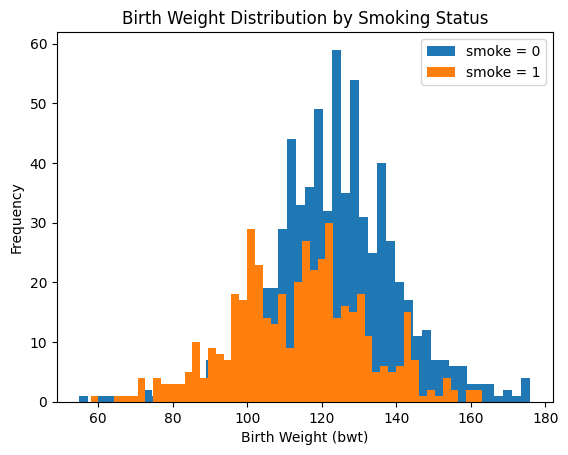

In [8]:
plt.figure()

plt.hist(df[df["smoke"] == 0]["bwt"], bins=50, alpha=1, label="smoke = 0")
plt.hist(df[df["smoke"] == 1]["bwt"], bins=50, alpha=1, label="smoke = 1")

plt.title("Birth Weight Distribution by Smoking Status")
plt.xlabel("Birth Weight (bwt)")
plt.ylabel("Frequency")
plt.legend()

plt.show()

3)  b) Creating a Boxplot with smoke on the x-axis and bwt on the y-axis.

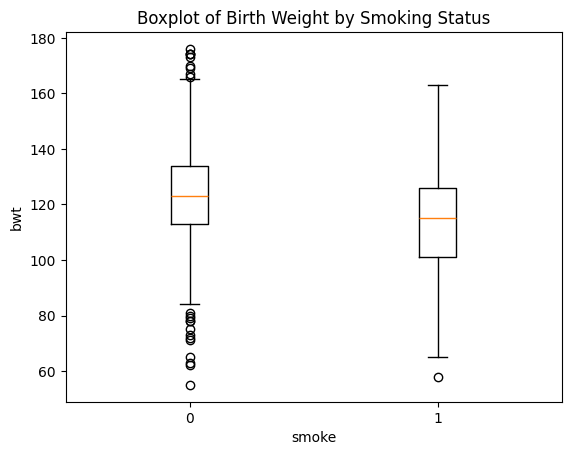

In [9]:
plt.figure()

data = [
    df[df["smoke"] == 0]["bwt"],
    df[df["smoke"] == 1]["bwt"]
]

plt.boxplot(data)

plt.xticks([1, 2], ["0", "1"])
plt.xlabel("smoke")
plt.ylabel("bwt")
plt.title("Boxplot of Birth Weight by Smoking Status")

plt.show()

4) Summary Statistics

In [10]:
print ("Summary statistics of bwt")

print ('\n')

summary = df.groupby("smoke")["bwt"].agg(
    Mean="mean",
    Median="median",
    Std_Dev="std",
    Skewness="skew",
    Kurtosis=lambda x: x.kurt()
)

print(summary)


Summary statistics of bwt


             Mean  Median    Std_Dev  Skewness  Kurtosis
smoke                                                   
0      123.085315   123.0  17.423695 -0.163130  1.032429
1      113.823913   115.0  18.275353 -0.022056 -0.033549


5) Looking at the histogram plot and the box plot for smoke 0 and smoke 1, it does look like smoking affects bwt. We feel that bwt is higher for smoke 0 on an average.

/tmp/ipykernel_1771/876556615.py:59: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  gestation_means = df.groupby(['gestation_group', 'smoke'])['bwt'].mean().unstack()
/tmp/ipykernel_1771/876556615.py:69: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_means = df.groupby(['age_group', 'smoke'])['bwt'].mean().unstack()


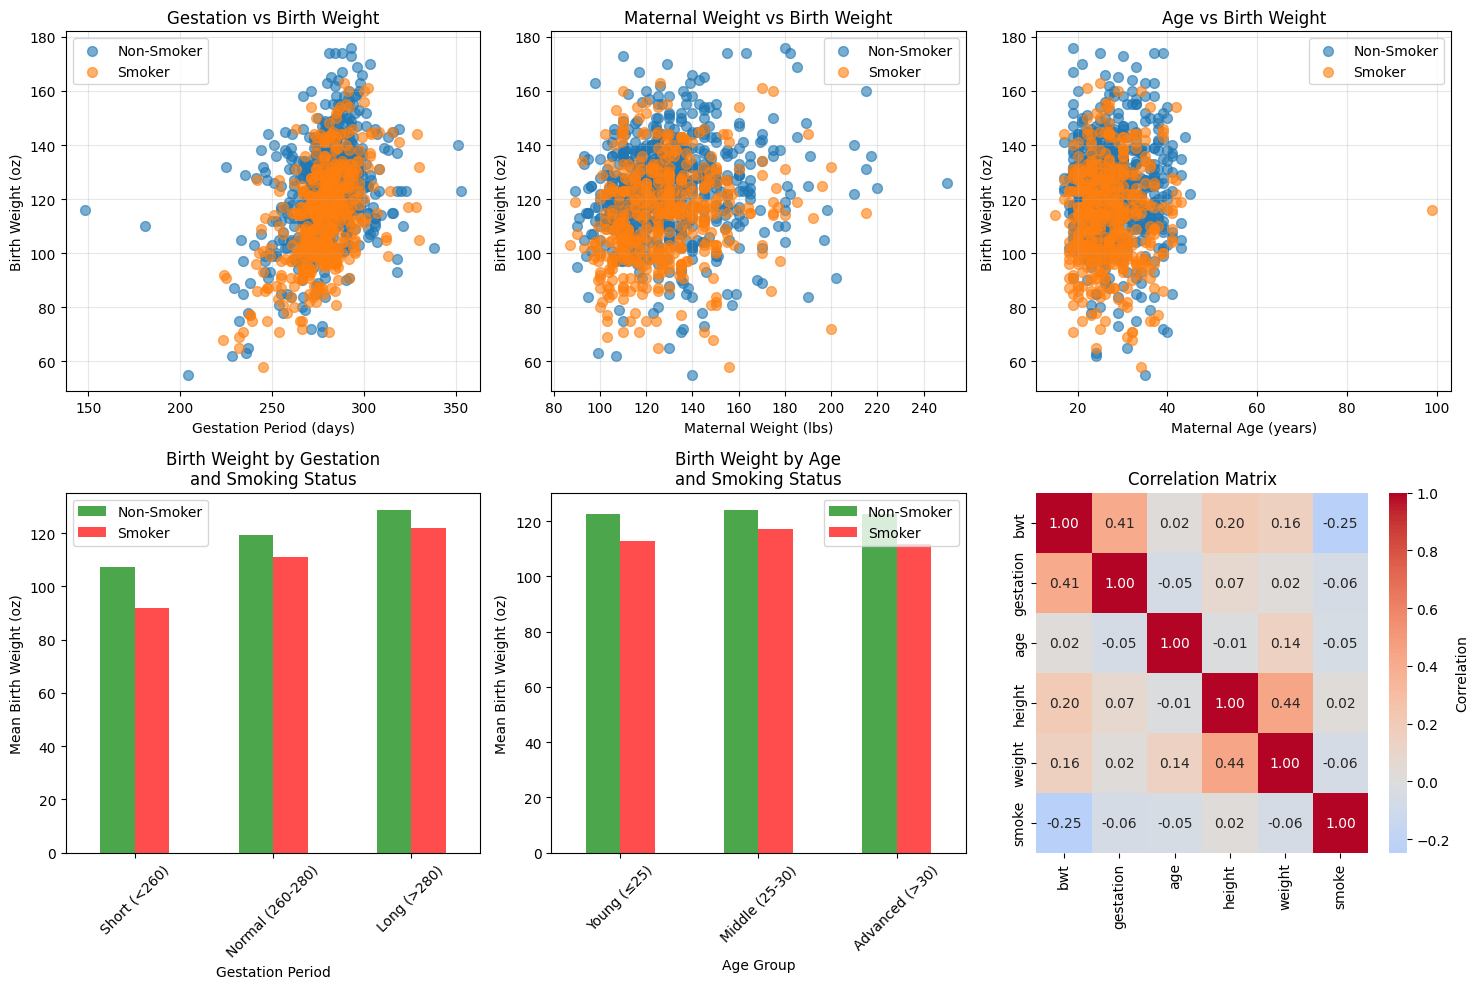

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create exploration dataframe
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# 1. Gestation period groups
df['gestation_group'] = pd.cut(df['gestation'],
                                bins=[0, 260, 280, 400],
                                labels=['Short (<260)', 'Normal (260-280)', 'Long (>280)'])

# 2. Maternal age groups
df['age_group'] = pd.cut(df['age'],
                         bins=[0, 25, 30, 100],
                         labels=['Young (≤25)', 'Middle (25-30)', 'Advanced (>30)'])

# PLOT 1: Gestation vs Birth Weight
ax = axes[0, 0]
for smoke_status in [0, 1]:
    mask = df['smoke'] == smoke_status
    ax.scatter(df[mask]['gestation'], df[mask]['bwt'],
              label='Non-Smoker' if smoke_status == 0 else 'Smoker',
              alpha=0.6, s=50)
ax.set_xlabel('Gestation Period (days)')
ax.set_ylabel('Birth Weight (oz)')
ax.set_title('Gestation vs Birth Weight')
ax.legend()
ax.grid(alpha=0.3)

# PLOT 2: Maternal Weight vs Birth Weight
ax = axes[0, 1]
for smoke_status in [0, 1]:
    mask = df['smoke'] == smoke_status
    ax.scatter(df[mask]['weight'], df[mask]['bwt'],
              label='Non-Smoker' if smoke_status == 0 else 'Smoker',
              alpha=0.6, s=50)
ax.set_xlabel('Maternal Weight (lbs)')
ax.set_ylabel('Birth Weight (oz)')
ax.set_title('Maternal Weight vs Birth Weight')
ax.legend()
ax.grid(alpha=0.3)

# PLOT 3: Age vs Birth Weight
ax = axes[0, 2]
for smoke_status in [0, 1]:
    mask = df['smoke'] == smoke_status
    ax.scatter(df[mask]['age'], df[mask]['bwt'],
              label='Non-Smoker' if smoke_status == 0 else 'Smoker',
              alpha=0.6, s=50)
ax.set_xlabel('Maternal Age (years)')
ax.set_ylabel('Birth Weight (oz)')
ax.set_title('Age vs Birth Weight')
ax.legend()
ax.grid(alpha=0.3)

# PLOT 4: Mean Birth Weight by Gestation Group
ax = axes[1, 0]
gestation_means = df.groupby(['gestation_group', 'smoke'])['bwt'].mean().unstack()
gestation_means.plot(kind='bar', ax=ax, color=['green', 'red'], alpha=0.7)
ax.set_xlabel('Gestation Period')
ax.set_ylabel('Mean Birth Weight (oz)')
ax.set_title('Birth Weight by Gestation\nand Smoking Status')
ax.legend(['Non-Smoker', 'Smoker'])
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45)

# PLOT 5: Mean Birth Weight by Age Group
ax = axes[1, 1]
age_means = df.groupby(['age_group', 'smoke'])['bwt'].mean().unstack()
age_means.plot(kind='bar', ax=ax, color=['green', 'red'], alpha=0.7)
ax.set_xlabel('Age Group')
ax.set_ylabel('Mean Birth Weight (oz)')
ax.set_title('Birth Weight by Age\nand Smoking Status')
ax.legend(['Non-Smoker', 'Smoker'])
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45)

# PLOT 6: Correlation Heatmap
ax = axes[1, 2]
corr_matrix = df[['bwt', 'gestation', 'age', 'height', 'weight', 'smoke']].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax,
            cbar_kws={'label': 'Correlation'})
ax.set_title('Correlation Matrix')

plt.tight_layout()
plt.savefig('exploratory_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

In [12]:
# Calculate BMI from height (inches) and weight (pounds)
df['bmi'] = (df['weight'] / (df['height'] ** 2)) * 703

# OR if you have metric units:
# BMI = weight_kg / (height_m ** 2)

In [30]:
# Load and clean the babies dataset into a dedicated DataFrame to avoid conflicts
df_babies = pd.read_csv("/content/babies.data", sep="\s+")
df_babies = df_babies[
    (df_babies["bwt"] != 999) &
    (df_babies["gestation"] != 999) &
    (df_babies["parity"] != 9) &
    (df_babies["height"] != 99) &
    (df_babies["weight"] != 999) &
    (df_babies["smoke"] != 9)
]

# Calculate BMI
df_babies['bmi'] = (df_babies['weight'] / (df_babies['height'] ** 2)) * 703

# Categorize BMI into standard groups
df_babies['bmi_category'] = pd.cut(df_babies['bmi'],
                                   bins=[0, 18.5, 24.9, 29.9, 100],
                                   labels=['Underweight (<18.5)', 'Normal (18.5-24.9)', 'Overweight (25-29.9)', 'Obese (≥30)'])

# Summary statistics by BMI category
bmi_stats = df_babies.groupby('bmi_category')['bwt'].agg([
    ('Count', 'count'),
    ('Mean', 'mean'),
    ('Median', 'median'),
    ('Std Dev', 'std')
])

print(bmi_stats.round(2))

                      Count    Mean  Median  Std Dev
bmi_category                                        
Underweight (<18.5)      84  115.29   117.0    16.86
Normal (18.5-24.9)      925  119.82   120.0    18.11
Overweight (25-29.9)    131  118.48   122.0    20.01
Obese (≥30)              35  123.71   125.0    19.71


<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1771/2978056160.py:2: SyntaxWarning: invalid escape sequence '\s'
  df_babies = pd.read_csv("/content/babies.data", sep="\s+")
/tmp/ipykernel_1771/2978056160.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bmi_stats = df_babies.groupby('bmi_category')['bwt'].agg([


#In Class Component

In [14]:
print (df['bwt'].unique())

[120 113 128 108 136 138 132 143 140 144 141 110 114 115  92 119 105 137
 122 131 103 146 125  93 130 134 107 129 111  87 155 145 102 124 106  75
 101 104  97 142 156 133  91 127 153 121  99 149 139  85 135 126  95 118
 100 152 117 112  94 109 147 160 123 116  96  90  98 150 154 173  81 148
  80  71  88 163  68  78  69 158 174 161 170  79 176  84  86 166 167  83
 165  77  62 162 164 151  72  58  89  55 159 169  65  73 157  63  82]


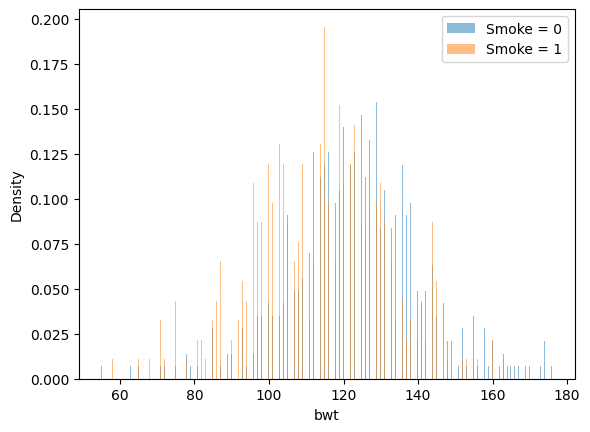

In [15]:
#Histogram of bwt for smoker = 1 and smoker = 0

# Split data
bwt_0 = df[df["smoke"] == 0]["bwt"]
bwt_1 = df[df["smoke"] == 1]["bwt"]

# Create bins with width 0.2
bins = np.arange(df["bwt"].min(),
                 df["bwt"].max() + 0.2,
                 0.2)

plt.figure()

plt.hist(bwt_0, bins=bins, alpha=0.5, density=True, label="Smoke = 0")
plt.hist(bwt_1, bins=bins, alpha=0.5, density=True, label="Smoke = 1")

plt.xlabel("bwt")
plt.ylabel("Density")
plt.legend()
plt.show()


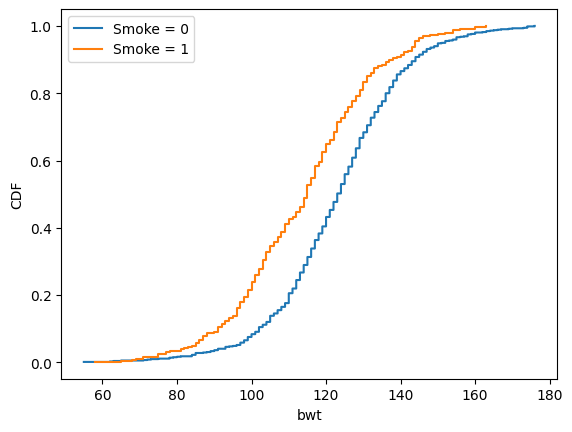

In [16]:
#Plotting the empirical cdf

# Split data
bwt_0 = df[df["smoke"] == 0]["bwt"].values
bwt_1 = df[df["smoke"] == 1]["bwt"].values

# Sort values
x0 = np.sort(bwt_0)
x1 = np.sort(bwt_1)

# ECDF values
y0 = np.arange(1, len(x0) + 1) / len(x0)
y1 = np.arange(1, len(x1) + 1) / len(x1)

plt.figure()

plt.step(x0, y0, where="post", label="Smoke = 0")
plt.step(x1, y1, where="post", label="Smoke = 1")

plt.xlabel("bwt")
plt.ylabel("CDF")
plt.legend()
plt.show()

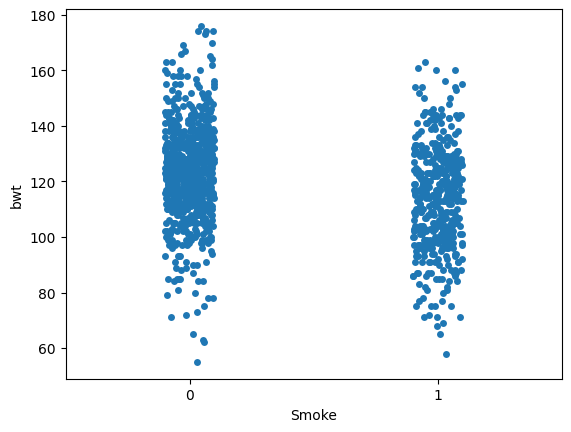

In [17]:
#Stripplot of the data with smoke on the x axis

plt.figure()
sns.stripplot(x="smoke", y="bwt", data=df, jitter=True)
plt.xlabel("Smoke")
plt.ylabel("bwt")
plt.show()

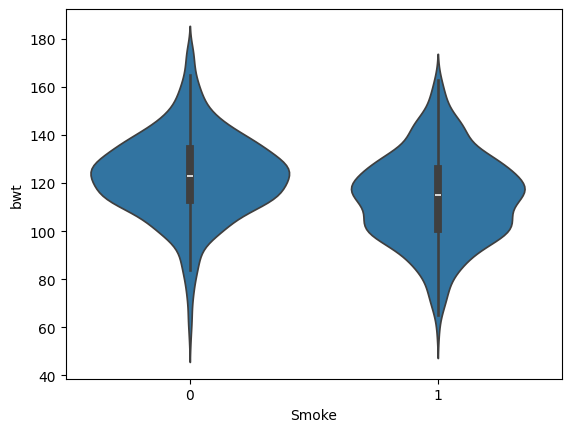

In [18]:
#Violin Plot

plt.figure()
sns.violinplot(x="smoke", y="bwt", data=df)
plt.xlabel("Smoke")
plt.ylabel("bwt")
plt.show()

#4 Part B: Video Game Analytics (Distribution Fitting)

In [19]:
#Loading the dataframe
cols = ["time", "like", "where", "freq", "busy",
        "educ", "sex", "age", "home", "math",
        "work", "own", "cdrom", "email", "grade"]

df = pd.read_csv("/content/video.data", sep="\s+")


<>:6: SyntaxWarning: invalid escape sequence '\s'
<>:6: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1771/4006245140.py:6: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv("/content/video.data", sep="\s+")


In [20]:
print (df.head(10))
print (df.shape)
print (df["time"].unique())

   time  like  where  freq  busy  educ  sex  age  home  math  work  own  \
0   2.0     3      3     2     0     1    0   19     1     0    10    1   
1   0.0     3      3     3     0     0    0   18     1     1     0    1   
2   0.0     3      1     3     0     0    1   19     1     0     0    1   
3   0.5     3      3     3     0     1    0   19     1     0     0    1   
4   0.0     3      3     4     0     1    0   19     1     1     0    0   
5   0.0     3      2     4     0     0    1   19     0     0    12    0   
6   0.0     4      3     4     0     0    1   20     1     1    10    1   
7   0.0     3      3     4     0     0    0   19     1     0    13    0   
8   2.0     3      2     1     1     1    1   19     0     0     0    0   
9   0.0     3      3     4     0     1    1   19     1     1     0    1   

   cdrom  email  grade  
0      0      1      4  
1      1      1      2  
2      0      1      3  
3      0      1      3  
4      0      1      3  
5      0      0      3  

1) Filtering out the students who have played for 0 hours

In [21]:
#No of students for whom time played is 0
(df["time"] == 0).sum()

np.int64(57)

In [22]:
#Removing rows where time = 0
df = df[df["time"] != 0]

print ((df["time"] == 0).sum())
print (df.shape)

0
(34, 15)


2) Method of moments


In [23]:
#Calculating the first moment of time
print (df["time"].mean())

#Calculating the second moment of time
print ((df["time"] ** 2).mean())


3.326470588235294
41.89735294117647


In [24]:
#Checking out the unique values of df['time']
print (np.sort((df['time'].unique())))

[ 0.1  0.5  1.   1.5  2.   3.   4.   5.  14.  30. ]


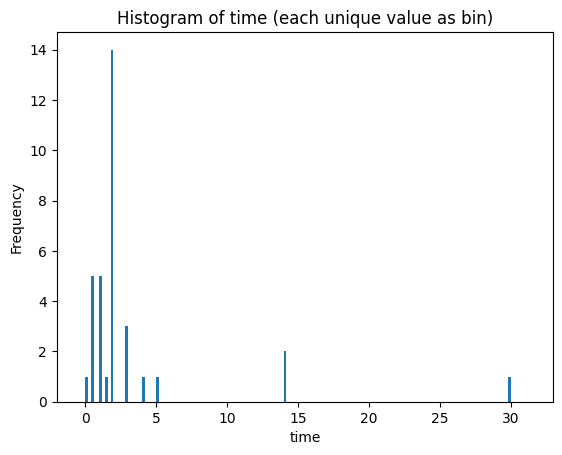

In [25]:
#Plotting a histogram for df['time'] for each unique value
time_data = df["time"].dropna()

bins = np.arange(time_data.min() - 0.5,
                 time_data.max() + 1.5,
                 0.2)

plt.figure()
plt.hist(time_data, bins=bins)
plt.xlabel("time")
plt.ylabel("Frequency")
plt.title("Histogram of time (each unique value as bin)")
plt.show()


Mom estimates obtained: 1) alpha = 0.36, 2) beta = 0.108

3) MLE estimate

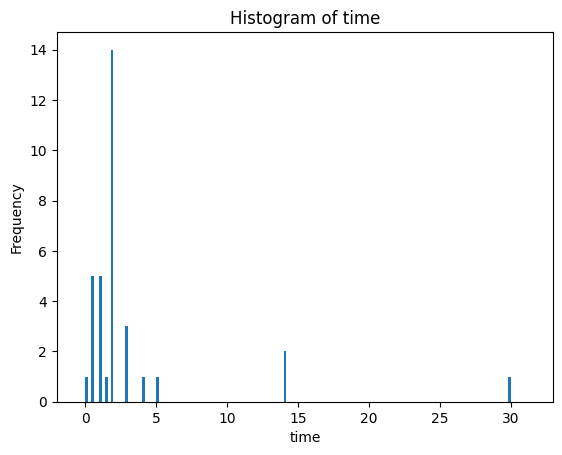

In [26]:
#Histogram of the time column
time_data = df["time"]

bins = np.arange(time_data.min() - 0.5,
                 time_data.max() + 1.5,
                 0.2)
plt.hist(time_data, bins=bins)
plt.xlabel("time")
plt.ylabel("Frequency")
plt.title("Histogram of time")
plt.show()

In [27]:
#Frequency of each unique entry
df["time"].value_counts()


,count
time,
2.0,14
0.5,5
1.0,5
3.0,3
14.0,2
0.1,1
4.0,1
30.0,1
1.5,1


4) Visual Fit

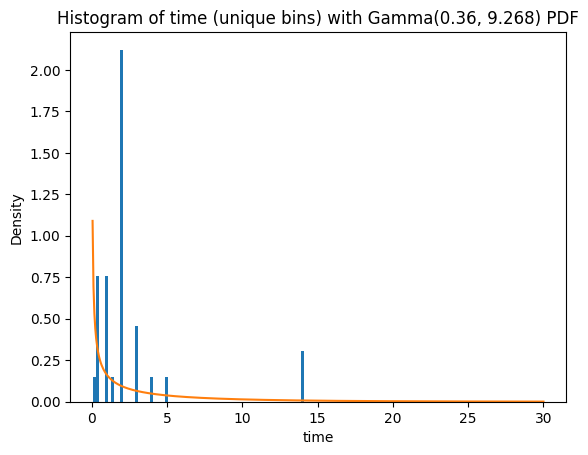

In [28]:
alpha = 0.36
beta = 0.108
scale = 9.268   # scipy uses scale = 1/rate

data = df["time"]

# Create bins so each unique integer value has its own bin
bins = np.arange(data.min(),
                 data.max(),
                 0.2)

plt.figure()

# Histogram with one bin per unique value
plt.hist(data, bins=bins, density=True)

# Overlay Gamma PDF
x = np.linspace(0, data.max(), 500)
pdf = gamma.pdf(x, a=alpha, scale=scale)
plt.plot(x, pdf)

plt.xlabel("time")
plt.ylabel("Density")
plt.title(f"Histogram of time (unique bins) with Gamma({alpha}, {scale}) PDF")

plt.show()
